<a href="https://colab.research.google.com/github/dhhung98-bot/Chess/blob/main/Copy_of_lesson04_student.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 第 4 堂：讓電腦自己學會下棋

上週我們學會替局面打分數，但發現兩個問題：

- 局面有 17 萬種，每個都下幾百盤，要跑 20 天
- 就算知道每個局面值幾分，電腦還是不知道「下一步走哪裡」

今天用一個聰明很多的方法解決：**Q-learning**。它有兩個重點：

1. 不只記「局面值幾分」，而是直接記「**在這個局面，走這一步**值幾分」
2. 不用等一盤下完，**每走一步就修正一點點**

今天結束時，你會親手訓練出一個會自己下棋的電腦，還會把它存成檔案。下週我們要把它放上網頁，讓大家都能跟它下棋。

上課方式一樣：**先猜再跑**、**換你講**、**改壞看看**，下課前錄 2 分鐘。

## 1. 準備

棋盤、裁判 `evaluate`、三種下法，還有上週寫的 `epsilon_greedy`，都在這一格。直接執行。

In [1]:
!pip install -q chess

import chess
import random
import pickle
import json
import matplotlib.pyplot as plt


def random_krk_board():
    while True:
        board = chess.Board(None)
        wk, wr, bk = random.sample(chess.SQUARES, 3)
        board.set_piece_at(wk, chess.Piece(chess.KING, chess.WHITE))
        board.set_piece_at(wr, chess.Piece(chess.ROOK, chess.WHITE))
        board.set_piece_at(bk, chess.Piece(chess.KING, chess.BLACK))
        board.turn = chess.WHITE
        if board.is_valid() and not board.is_game_over():
            return board


class KRKEnv:
    def __init__(self, max_steps=50, step_penalty=0.01):
        self.max_steps = max_steps
        self.step_penalty = step_penalty

    def reset(self, fen=None):
        self.board = random_krk_board() if fen is None else chess.Board(fen)
        self.steps = 0
        self.done = False
        return self.get_state()

    def get_state(self):
        wk = self.board.king(chess.WHITE)
        bk = self.board.king(chess.BLACK)
        rooks = self.board.pieces(chess.ROOK, chess.WHITE)
        wr = list(rooks)[0] if rooks else None
        return (wk, wr, bk)

    def legal_actions(self):
        return list(self.board.legal_moves)

    def is_terminal(self):
        return self.done

    def step(self, move):
        self.board.push(move)
        self.steps += 1
        if self.board.is_checkmate():
            self.done = True
            return self.get_state(), 1.0, True
        if self.board.is_stalemate():
            self.done = True
            return self.get_state(), -1.0, True
        self.board.push(random.choice(list(self.board.legal_moves)))
        if self.board.is_insufficient_material():
            self.done = True
            return self.get_state(), -1.0, True
        if self.steps >= self.max_steps:
            self.done = True
            return self.get_state(), -self.step_penalty, True
        return self.get_state(), -self.step_penalty, False


def game_result(env):
    if env.board.is_checkmate():
        return "win"
    if env.board.is_stalemate():
        return "stalemate"
    if env.board.is_insufficient_material():
        return "rook lost"
    return "timeout"


def evaluate(policy, n=3000, seed=0, max_steps=50, step_penalty=0.01):
    random.seed(seed)
    env = KRKEnv(max_steps=max_steps, step_penalty=step_penalty)
    count = {"win": 0, "stalemate": 0, "rook lost": 0, "timeout": 0}
    total = 0
    for i in range(n):
        env.reset()
        G = 0
        while not env.is_terminal():
            state, reward, done = env.step(policy(env))
            G += reward
        count[game_result(env)] += 1
        total += G
    return count, round(count["win"] / n * 100, 1), round(total / n, 3)


def random_policy(env):
    return random.choice(env.legal_actions())


def find_mate(env):
    for move in env.legal_actions():
        env.board.push(move)
        mate = env.board.is_checkmate()
        env.board.pop()
        if mate:
            return move
    return None


def rook_is_safe(board):
    rooks = board.pieces(chess.ROOK, chess.WHITE)
    if not rooks:
        return False
    sq = list(rooks)[0]
    return (not board.is_attacked_by(chess.BLACK, sq)) or board.is_attacked_by(chess.WHITE, sq)


def safe_policy(env):
    move = find_mate(env)
    if move is not None:
        return move
    good = []
    for move in env.legal_actions():
        env.board.push(move)
        if rook_is_safe(env.board) and not env.board.is_stalemate():
            good.append(move)
        env.board.pop()
    return random.choice(good) if good else random.choice(env.legal_actions())


def epsilon_greedy(best_move, actions, eps):
    if random.random() < eps:
        return random.choice(actions)
    return best_move

print("準備好了")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
準備好了


## 2. Q 表：替「這一步」打分數

上週我們替**局面**打分數。可是下棋時真正要決定的是「**這一步走哪裡**」。

所以今天換個方式：直接替「在這個局面，走這一步」打分數。把所有分數整理成一張大表，就叫做 **Q 表**。（Q 是 quality 的意思，代表「這一步有多好」。）

想像手搖飲店的菜單評分表：

| 心情（局面） | 珍奶 | 綠茶 | 檸檬汁 |
|---|---|---|---|
| 好熱 | 0.3 | 0.6 | **0.9** |
| 好累 | **0.8** | 0.2 | 0.4 |

每一列是一種心情，每一欄是一種飲料，格子裡是「這時候點這杯有多好」。要點飲料時，看你現在那一列，挑分數最高的那格。

下棋的 Q 表一模一樣：每一列是一個局面，每一欄是一種走法。

在 Python 裡，我們用「dict 裡面再放 dict」來存：

In [2]:
# 一個很小的 Q 表範例：只有一個局面，三種走法
Q_example = {
    (44, 48, 60): {"a7a8": 0.95, "e6d6": 0.10, "a7a1": -0.30},
}

state = (44, 48, 60)
print("這個局面的所有走法：", Q_example[state])
print("走 a7a8 的分數：", Q_example[state]["a7a8"])

這個局面的所有走法： {'a7a8': 0.95, 'e6d6': 0.1, 'a7a1': -0.3}
走 a7a8 的分數： 0.95


還沒學過的格子怎麼辦？一律當成 0。下面兩個小工具會一直用到：

- `get_q`：查一格的分數，沒有就回傳 0
- `best_move`：在這個局面，挑分數最高的那一步

In [3]:
def get_q(Q, state, move):
    return Q.get(state, {}).get(move.uci(), 0.0)


def best_move(Q, state, actions):
    best = actions[0]
    for move in actions:
        if get_q(Q, state, move) > get_q(Q, state, best):
            best = move
    return best

**換你講**：Q 表和上週的「局面分數」差在哪裡？為什麼 Q 表比較好用來決定下一步？

## 3. 怎麼把 Q 表填對？邊下邊修正

一開始 Q 表是空的，全部當 0。電腦要怎麼把它填對？

**用考試來想**：你預期這次考 60 分，結果考了 80 分。下次你會預期幾分？大部分人不會一下子改成 80，因為這次可能只是運氣好，而是**往 80 的方向調一點**，例如 70。

電腦也是這樣，每走一步就做三件事：

1. **舊的猜測**：表裡這一格原本是幾分
2. **新的參考答案**：走完這一步拿到的分數，加上「下一個局面最好的那一步」打九折
3. **往新答案靠近一點**：不是直接換掉，只修正一部分

「修正一部分」修多少？用 **α**（希臘字母，唸「阿法」）來決定。α = 0.5 就是修一半。

### 先手算

- 表裡原本是 0.50
- 這一步拿到 0 分，下一個局面最好的那一步是 0.8，γ = 0.9
- 新的參考答案 = 0 + 0.9 × 0.8 = ？
- 差距 = 新的參考答案 − 0.50 = ？
- 修正後 = 0.50 + 0.5 × 差距 = ？

我算出來：新的參考答案 = ＿＿＿，差距 = ＿＿＿，修正後 = ＿＿＿

### 練習 1：把手算寫成程式

只有兩行要寫：

1. `target`（新的參考答案）：如果這盤已經結束，後面沒有下一步了，參考答案就是 `reward`；不然就是 `reward + gamma × 下一個局面最好的分數`
2. 修正後的分數：`old + alpha * (target - old)`

In [4]:
def update(Q, state, move, reward, next_state, next_actions, done, alpha=0.5, gamma=0.9):
    old = get_q(Q, state, move)

    if done:
        target = reward
    else:
        best_next = max(get_q(Q, next_state, a) for a in next_actions)
        # TODO: 算出新的參考答案 target
        target = reward + gamma * best_next

    # TODO: 算出修正後的分數，存回 Q 表
    Q.setdefault(state, {})[move.uci()] = old +alpha * (target - old)
    # 提示：Q.setdefault(state, {})[move.uci()] = 修正後的分數

用剛剛手算的數字檢查。下面這格會造一個小例子：表裡原本 0.50，下一個局面最好的是 0.8。

In [5]:
move = chess.Move.from_uci("a7a8")
next_move = chess.Move.from_uci("e6e7")
Q_test = {
    "局面1": {"a7a8": 0.50},
    "局面2": {"e6e7": 0.80},
}
update(Q_test, "局面1", move, reward=0, next_state="局面2", next_actions=[next_move], done=False)
print("修正後：", Q_test["局面1"]["a7a8"])    # 跟你手算的一樣嗎？

修正後： 0.6100000000000001


**改壞看看**：把 `update` 那行的 `alpha` 改成 1（加上 `alpha=1`），再跑一次檢查格，修正後變多少？改成 0 呢？

- α = 1 是什麼意思？
- α = 0 會發生什麼事？

**換你講**：為什麼不要每次都直接換成新的參考答案？

## 4. 訓練迴圈

把所有東西組起來就是訓練。每一盤棋：

1. 開一盤新的
2. 用 `epsilon_greedy` 選一步（大部分選 Q 表裡最好的，偶爾亂試）
3. 走這一步，看拿到幾分、到了哪個新局面
4. 用 `update` 修正 Q 表
5. 重複，直到這盤結束

亂試的機率 ε 一開始是 1（全部亂試，因為什麼都還不會），之後慢慢降到 0.05。

這一格大部分寫好了，**先從上往下讀一次**，每一行在做什麼都要看得懂。

In [6]:
def train(episodes, alpha=0.5, gamma=0.9, eps_start=1.0, eps_end=0.05, seed=0, report_every=5000, make_env=KRKEnv):
    random.seed(seed)
    Q = {}
    env = make_env()          # 開一個新環境（預設是西洋棋）
    win_history = []          # 每一盤有沒有贏，畫圖用

    for ep in range(episodes):
        # 亂試的機率：從 eps_start 慢慢降到 eps_end
        eps = max(eps_end, eps_start - (eps_start - eps_end) * ep / (episodes * 0.8))

        state = env.reset()
        actions = env.legal_actions()
        while not env.is_terminal():
            move = epsilon_greedy(best_move(Q, state, actions), actions, eps)
            next_state, reward, done = env.step(move)
            next_actions = [] if done else env.legal_actions()
            update(Q, state, move, reward, next_state, next_actions, done, alpha, gamma)
            state, actions = next_state, next_actions

        win_history.append(1 if reward == 1.0 else 0)
        if (ep + 1) % report_every == 0:
            recent = sum(win_history[-report_every:]) / report_every * 100
            print(f"第 {ep + 1} 盤，最近 {report_every} 盤的勝率 {recent:.1f}%，亂試機率 {eps:.2f}，Q 表有 {len(Q)} 個局面")

    return Q, win_history

**換你講**：指著程式，說出哪一行是「選一步」、哪一行是「走一步」、哪一行是「修正」。

## 5. 開始訓練

先訓練 4 萬盤，大約要 3 到 5 分鐘。

**先猜再跑**：訓練完以後，勝率會是多少？會比上週「不送車」的 12% 高嗎？

我猜：

In [7]:
Q, win_history = train(40000)

第 5000 盤，最近 5000 盤的勝率 0.7%，亂試機率 0.85，Q 表有 94972 個局面
第 10000 盤，最近 5000 盤的勝率 1.1%，亂試機率 0.70，Q 表有 128455 個局面
第 15000 盤，最近 5000 盤的勝率 1.2%，亂試機率 0.55，Q 表有 142765 個局面
第 20000 盤，最近 5000 盤的勝率 1.9%，亂試機率 0.41，Q 表有 150971 個局面
第 25000 盤，最近 5000 盤的勝率 3.7%，亂試機率 0.26，Q 表有 156421 個局面
第 30000 盤，最近 5000 盤的勝率 6.5%，亂試機率 0.11，Q 表有 160477 個局面
第 35000 盤，最近 5000 盤的勝率 9.9%，亂試機率 0.05，Q 表有 163638 個局面
第 40000 盤，最近 5000 盤的勝率 12.0%，亂試機率 0.05，Q 表有 166220 個局面


等它跑的時候，看看每 5000 盤印出來的數字有什麼變化。

跑完以後，把勝率畫成一條線。這叫**學習曲線**，可以看出電腦是不是越來越強。

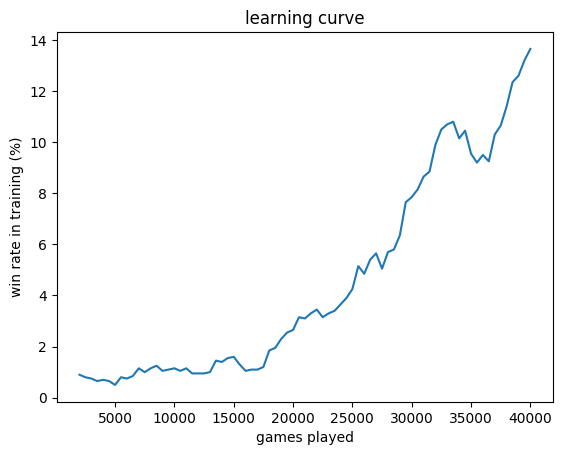

In [8]:
window = 2000
curve = []
for i in range(window, len(win_history) + 1, 500):
    curve.append(sum(win_history[i - window:i]) / window * 100)

plt.plot(range(window, len(win_history) + 1, 500), curve)
plt.xlabel("games played")
plt.ylabel("win rate in training (%)")
plt.title("learning curve")
plt.show()

**換你講**：曲線一開始很低、後來慢慢上升。為什麼一開始這麼低？（提示：一開始亂試的機率是多少？）

## 6. 交給裁判，跟前幾週比一比

讓訓練好的電腦參賽時，**不再亂試**，每一步都選 Q 表裡最好的。

In [9]:
def make_q_policy(Q):
    def policy(env):
        state = env.get_state()
        return best_move(Q, state, env.legal_actions())
    return policy

q_policy = make_q_policy(Q)
print("亂下　　：", evaluate(random_policy)[1], "%")
print("不送車　：", evaluate(safe_policy)[1], "%")
print("Q 表 4 萬：", evaluate(q_policy)[1], "%")

亂下　　： 0.7 %
不送車　： 12.3 %
Q 表 4 萬： 14.8 %


**換你講**：它是怎麼學會的？我們有沒有教它任何下棋的規則？

第 16 步


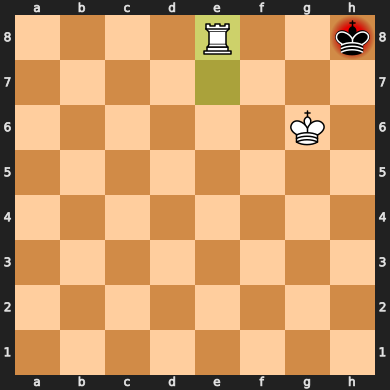

結果： win


In [11]:
from IPython.display import display, clear_output
import time

def watch_game(policy, seed=7, delay=1.0):
    random.seed(seed)
    env = KRKEnv()
    env.reset()
    display(env.board)
    while not env.is_terminal():
        time.sleep(delay)
        clear_output(wait=True)
        env.step(policy(env))
        print("第", env.steps, "步")
        display(env.board)
    print("結果：", game_result(env))

with open("q_120k.pkl", "rb") as f:
    Q_big = pickle.load(f)
print(evaluate(make_q_policy(Q_big))[1], "%")
watch_game(make_q_policy(Q_big))

## 7. 看電腦下一盤

把電腦下的每一步都畫出來，看看它在想什麼。

第 18 步


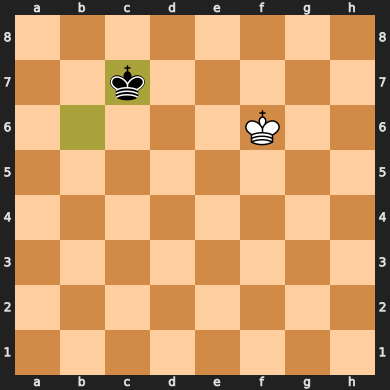

結果： rook lost


In [12]:
from IPython.display import display, clear_output
import time

def watch_game(policy, seed=7, delay=1.0):
    random.seed(seed)
    env = KRKEnv()
    env.reset()
    display(env.board)
    while not env.is_terminal():
        time.sleep(delay)
        clear_output(wait=True)
        env.step(policy(env))
        print("第", env.steps, "步")
        display(env.board)
    print("結果：", game_result(env))

watch_game(q_policy)

**換你講**：它有沒有什麼「計畫」？例如先把車移到哪裡、王往哪裡走？如果是你，你會怎麼下？

（如果這盤很快就送車或拖到時間到，把 `seed=7` 改成別的數字多看幾盤。）

## 8. 把訓練好的電腦存起來

訓練很花時間，要把成果存成檔案，下次直接拿來用。

我們存兩種檔案：

- `q_table.pkl`：完整的 Q 表，下次可以繼續訓練或比較
- `policy.json`：**每個局面最好的那一步**。下週要把它放上網頁，讓網頁可以跟你下棋

`policy.json` 會比 Q 表小很多，因為每個局面只留一步。

In [13]:
def save_model(Q, name):
    # 1. 存完整的 Q 表
    with open(name + ".pkl", "wb") as f:
        pickle.dump(Q, f)

    # 2. 存「每個局面最好的那一步」，給網頁用
    policy = {}
    for state, moves in Q.items():
        wk, wr, bk = state
        key = f"{wk},{wr},{bk}"
        policy[key] = max(moves, key=moves.get)
    with open(name + "_policy.json", "w") as f:
        json.dump(policy, f)

    print("存好了：", name + ".pkl", "和", name + "_policy.json", "，一共", len(policy), "個局面")

save_model(Q, "q_40k")

存好了： q_40k.pkl 和 q_40k_policy.json ，一共 166220 個局面


存好的檔案在 Colab 左邊的「檔案」欄（資料夾圖示）。在檔案上按右鍵就可以下載。

注意：Colab 關掉以後，這些檔案會被清掉，一定要下載下來。

## 9. 回家挑戰：訓練出勝率超過 80% 的電腦

今天的 4 萬盤還不夠強。回家你要自己調設定，訓練出一個**用裁判測勝率超過 80%** 的電腦。

### 你可以調的設定

| 設定 | 意思 | 今天用的值 | 可以試試 |
|---|---|---|---|
| `episodes` | 訓練幾盤 | 40000 | 更多盤 |
| `gamma` | 打幾折（多看重未來） | 0.9 | 0.8、0.95、0.99 |
| `alpha` | 每次修正多少 | 0.5 | 0.1、0.3、0.7 |
| `eps_end` | 最後還會亂試多少 | 0.05 | 0.01、0.1 |

例如：

```python
Q2, history2 = train(80000, gamma=0.95, alpha=0.5)
print(evaluate(make_q_policy(Q2))[1], "%")
```

### 規則

1. **一次只改一個設定**，才知道是哪個有用（第 2 週學的）
2. 每次都用 `evaluate` 測，盤數和種子不要改，才公平
3. 每試一次，就把結果記在下面的表格裡
4. 找到超過 80% 的，用 `save_model(Q, "best")` 存起來，把 `best_policy.json` 上傳到 GitHub

訓練盤數多的時候會跑很久（十幾分鐘到半小時）。可以讓它跑著，去做別的事，但 Colab 的分頁不要關。

### 實驗紀錄

| 第幾次 | 訓練幾盤 | gamma | alpha | eps_end | 訓練多久 | 勝率 |
|---|---|---|---|---|---|---|
| 1 | 40000 | 0.9 | 0.5 | 0.05 | | |
| 2 | | | | | | |
| 3 | | | | | | |

## 10. 總複習：你已經學會一整套強化學習了

### 強化學習就是一直轉這個圈

```
   電腦（Agent）──選一步（Action）──▶ 棋盤（Environment）
        ▲                                   │
        └──── 新局面（State）＋ 分數（Reward）─┘
```

電腦看局面、選一步；棋盤（加上亂走的黑王）回應，給它新局面和分數；電腦用分數修正 Q 表，再選下一步。一盤接一盤，越轉越強。

### 這四週，你做了這個圈的哪一塊？

| 週 | 你做了什麼 | 在圈裡是哪一塊 |
|---|---|---|
| 第 1 週 | 用程式擺棋盤、判斷輸贏、給分數 | 環境（Environment）和分數（Reward） |
| 第 2 週 | 寫規則下法：亂下、能將死就將死、不送車；做裁判 `evaluate` | 下法規則（Policy）和怎麼評分 |
| 第 3 週 | 替局面打分數、打折 γ、亂試 ε | 之後的總分（Return）、局面值幾分（Value） |
| 第 4 週 | Q 表、邊下邊修正、自己訓練 | 讓電腦自己學出 Policy（Q-learning） |


### 十個一定要知道的詞

以後看文章、聽演講、面試，別人會用右邊的英文。你其實每一個都寫過程式了。

| 我們的叫法 | 正式名稱 | 在我們的程式裡 |
|---|---|---|
| 局面 | State | `env.get_state()`，(白王, 白車, 黑王) |
| 下法 | Action | `env.legal_actions()` 裡的一步 |
| 分數 | Reward | `env.step()` 回傳的分數：將死 +1、送車或逼和 −1、每步 −0.01 |
| 環境 | Environment | `KRKEnv`：棋盤加上亂走的黑王 |
| 下法規則 | Policy | `random_policy`、`safe_policy`、`make_q_policy(Q)` |
| 之後的總分 | Return | 第 3 週一步一步往前打折加起來的那個數字 |
| 打折 γ | Discount factor | `gamma` |
| 這一步值幾分 | Q-value | `Q[局面][下法]`、`get_q` |
| 移多少 α | Learning rate | `alpha` |
| 亂試 ε | Exploration（ε-greedy） | `epsilon_greedy`、`eps` |
| 一盤 | Episode | `train` 裡面的 `for ep in range(episodes)` |


**換你講**：不看上面的表，用這幾個英文詞講一次強化學習在做什麼：Agent、Environment、State、Action、Reward、Policy。

### 換一個遊戲：走迷宮

強化學習最厲害的地方是：**學習的方法不用改，只要換環境**。

想換一個遊戲，只要想清楚四件事：

| 要自己決定的 | 西洋棋殘局 | 走迷宮 |
|---|---|---|
| 局面是什麼 | (白王, 白車, 黑王) | 你現在在哪一格 |
| 可以做哪些動作 | 所有合法的棋 | 上、下、左、右 |
| 怎麼給分 | 將死 +1、送車 −1、每步 −0.01 | 走到終點 +1、撞牆 −0.1、每步 −0.01 |
| 一盤什麼時候結束 | 將死、送車、逼和、50 步 | 走到終點，或 100 步 |

然後寫成一個環境，有 `reset`（開新的一盤）、`legal_actions`（能做哪些動作）、`step`（走一步，回傳新局面和分數）、`is_terminal`（結束了沒）。

下面這格就是迷宮的環境，直接執行。看看它跟 `KRKEnv` 長得多像。

In [14]:
# 迷宮的動作是「上、下、左、右」這幾個字。
# Q 表的程式會呼叫 .uci() 把動作變成文字，所以做一個「有 .uci() 的文字」，舊程式就能直接用。
class Action(str):
    def uci(self):
        return str(self)

UP, DOWN, LEFT, RIGHT = Action("上"), Action("下"), Action("左"), Action("右")
DIRECTIONS = {"上": (-1, 0), "下": (1, 0), "左": (0, -1), "右": (0, 1)}

# S 是起點，G 是終點，# 是牆
MAZE = ["S..#..",
        "##.#.#",
        "......",
        ".####.",
        "....#G"]


class MazeEnv:
    def __init__(self, max_steps=100, step_penalty=0.01, wall_reward=-0.1):
        self.max_steps = max_steps
        self.step_penalty = step_penalty
        self.wall_reward = wall_reward

    def reset(self):
        self.pos = (0, 0)        # 從 S 出發
        self.steps = 0
        self.done = False
        return self.get_state()

    def get_state(self):
        return self.pos          # 局面：你現在在第幾列、第幾行

    def legal_actions(self):
        return [UP, DOWN, LEFT, RIGHT]

    def is_terminal(self):
        return self.done

    def step(self, action):
        r, c = self.pos
        dr, dc = DIRECTIONS[action]
        nr, nc = r + dr, c + dc
        self.steps += 1

        if 0 <= nr < len(MAZE) and 0 <= nc < len(MAZE[0]) and MAZE[nr][nc] != "#":
            self.pos = (nr, nc)
            reward = -self.step_penalty      # 正常走一步，扣一點點
        else:
            reward = self.wall_reward        # 撞牆，留在原地

        if MAZE[self.pos[0]][self.pos[1]] == "G":
            self.done = True
            return self.get_state(), 1.0, True
        if self.steps >= self.max_steps:
            self.done = True
            return self.get_state(), reward, True
        return self.get_state(), reward, False


def show_path(Q, make_env=MazeEnv):
    env = make_env()
    state = env.reset()
    path = [state]
    while not env.is_terminal():
        state, reward, done = env.step(best_move(Q, state, env.legal_actions()))
        path.append(state)
    grid = [list(row) for row in MAZE]
    for r, c in path:
        if grid[r][c] == ".":
            grid[r][c] = "*"
    print("\n".join(" ".join(row) for row in grid))
    print("走了", env.steps, "步，", "到終點了！" if MAZE[state[0]][state[1]] == "G" else "沒走到終點")


print("迷宮準備好了")

迷宮準備好了


現在用**一模一樣的 `train`** 來練迷宮。唯一的差別是告訴它：開新的一盤時，開的是迷宮。

**先猜再跑**：西洋棋要練好幾萬盤，迷宮要練幾盤才會？

我猜：

In [19]:
Q_maze, maze_history = train(100, make_env=MazeEnv, report_every=100)
show_path(Q_maze)

第 100 盤，最近 100 盤的勝率 92.0%，亂試機率 0.05，Q 表有 19 個局面
S * * # . .
# # * # . #
. . * * * *
. # # # # *
. . . . # G
走了 9 步， 到終點了！


**換你講**：我們改了 `get_q`、`update`、`train` 哪幾行？為什麼它換了一個遊戲還是學得會？

### 改壞看看：分數給錯會怎樣？

**分數給什麼，電腦就學什麼，不一定是你心裡想的。**

把「撞牆 −0.1」改成「撞牆 +0.1」，再練一次。

**先猜再跑**：它還會走到終點嗎？

（`lambda: MazeEnv(wall_reward=0.1)` 是一個很短的函式，意思是「每次開新的一盤，就開一個撞牆會加分的迷宮」。）

我猜：

In [20]:
Q_bad, bad_history = train(500, make_env=lambda: MazeEnv(wall_reward=0.1), report_every=100)
show_path(Q_bad, make_env=lambda: MazeEnv(wall_reward=0.1))

第 100 盤，最近 100 盤的勝率 15.0%，亂試機率 0.76，Q 表有 19 個局面
第 200 盤，最近 100 盤的勝率 5.0%，亂試機率 0.53，Q 表有 19 個局面
第 300 盤，最近 100 盤的勝率 2.0%，亂試機率 0.29，Q 表有 19 個局面
第 400 盤，最近 100 盤的勝率 2.0%，亂試機率 0.05，Q 表有 19 個局面
第 500 盤，最近 100 盤的勝率 2.0%，亂試機率 0.05，Q 表有 19 個局面
S . . # . .
# # . # . #
. . . . . .
. # # # # .
. . . . # G
走了 100 步， 沒走到終點


**換你講**：電腦為什麼不去終點了？它笨嗎？如果是你在設計分數，要怎麼避免這種事？

### 換你想：你想讓電腦學什麼？

挑一個你有興趣的遊戲（井字遊戲、貪食蛇、2048、Flappy Bird……都可以），把四格填完：

| 要自己決定的 | 我的遊戲：＿＿＿＿ |
|---|---|
| 局面是什麼 | |
| 可以做哪些動作 | |
| 怎麼給分 | |
| 一盤什麼時候結束 | |

想想看：你的分數會不會被電腦鑽漏洞？局面會不會多到表格裝不下？

### 換你講：30 秒介紹你的專案

如果大學教授問你：「這個專案在做什麼？」照著下面填空講一次，再不看稿講一次。

> 我做了一個會下西洋棋殘局的 AI。它一開始只會亂下，勝率＿＿。我用＿＿的方法，讓它自己下了＿＿盤，勝率變成＿＿。過程中最難的是＿＿，我是靠＿＿解決的。

回家挑戰做完，把數字換成你最好的成績，這段就可以直接寫進備審資料。

### 專案摘要（下週要給 AI 看的）

下週我們要請 AI 寫程式工具讀你這四週的筆記本，幫你做出一個可以跟你的電腦下棋的網頁。AI 會讀這一段，所以這段要寫清楚。

- **遊戲**：西洋棋殘局「王車殺單王」（KRK）。白方有王和車，黑方只有王。白方先走，目標是在 50 步內將死黑王。
- **白方（我們訓練的電腦）**：看 `policy.json` 決定每一步。
- **黑方**：訓練時是亂走（從合法的走法裡隨便挑一步）。網頁上可以讓人類當黑方。
- **局面的寫法**：三個格子編號 `(白王, 白車, 黑王)`。格子編號 0 到 63，`a1 = 0`、`b1 = 1`……`h1 = 7`、`a2 = 8`……`h8 = 63`（跟 python-chess 一樣）。
- **`policy.json` 的格式**：`{"白王,白車,黑王": "走法"}`，例如 `{"4,0,60": "a1a8"}`，意思是白王在 e1、白車在 a1、黑王在 e8 時，車走到 a8。走法是 UCI 格式（起點格加終點格）。
- **注意**：`policy.json` 只記了訓練時碰過的局面。如果遇到沒記到的局面，網頁要有備案，例如從合法走法裡隨便挑一步。
- **我最好的成績**：用＿＿盤訓練、gamma＝＿＿，勝率＿＿%，檔案是 `best_policy.json`。

## 11. 存到 GitHub

1. 「檔案 → 在 GitHub 中儲存副本」，檔名 `lesson04.ipynb`
2. 在 README 的結果表加一列：`Q-learning（4 萬盤）｜勝率 ＿＿%`
3. 回家做到 80% 以後，再加一列，並把 `best_policy.json` 上傳到 GitHub
4. 把「十個詞」那張表和你的 30 秒專案介紹，也貼進 README

## 下課前：錄 2 分鐘

1. 今天做了什麼？
2. 哪裡最難？你是怎麼弄懂的？
3. 用你自己的話說：電腦是怎麼「邊下邊學」的？